### IMPORTATION ET CREATION DU DATAFRAME

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("AB_NYC_2019.csv")

### PREVISUALISATION ET INFORMATIONS DE BASE

In [91]:
print("---Vue d'ensemble---")
df.head()

---Vue d'ensemble---


,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,2539,Clean & quiet apt home by the park,2787,John,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,1,9,2018-10-19,0.21,6,365
1,2595,Skylit Midtown Castle,2845,Jennifer,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225,1,45,2019-05-21,0.38,2,355
2,3647,THE VILLAGE OF HARLEM....NEW YORK !,4632,Elisabeth,Manhattan,Harlem,40.80902,-73.94190,Private room,150,3,0,NaN,NaN,1,365
3,3831,Cozy Entire Floor of Brownstone,4869,LisaRoxanne,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89,1,270,2019-07-05,4.64,1,194
4,5022,Entire Apt: Spacious Studio/Loft by central park,7192,Laura,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80,10,9,2018-11-19,0.10,1,0


In [6]:
print("\n---Infos sur les colonnes---")
df.info()

print("\n--- Verification cellules manquantes---")
df.isnull().sum()


---Infos sur les colonnes---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48895 entries, 0 to 48894
Data columns (total 16 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id                              48895 non-null  int64  
 1   name                            48879 non-null  object 
 2   host_id                         48895 non-null  int64  
 3   host_name                       48874 non-null  object 
 4   neighbourhood_group             48895 non-null  object 
 5   neighbourhood                   48895 non-null  object 
 6   latitude                        48895 non-null  float64
 7   longitude                       48895 non-null  float64
 8   room_type                       48895 non-null  object 
 9   price                           48895 non-null  int64  
 10  minimum_nights                  48895 non-null  int64  
 11  number_of_reviews               48895 non-null  int64  
 12  la

id                                    0
name                                 16
host_id                               0
host_name                            21
neighbourhood_group                   0
neighbourhood                         0
latitude                              0
longitude                             0
room_type                             0
price                                 0
minimum_nights                        0
number_of_reviews                     0
last_review                       10052
reviews_per_month                 10052
calculated_host_listings_count        0
availability_365                      0
dtype: int64

### ANALYSE SUR LES PRIX

In [2]:
df['price'].describe()

count    48895.000000
mean       152.720687
std        240.154170
min          0.000000
25%         69.000000
50%        106.000000
75%        175.000000
max      10000.000000
Name: price, dtype: float64

#### Y a t'il des outliners ?

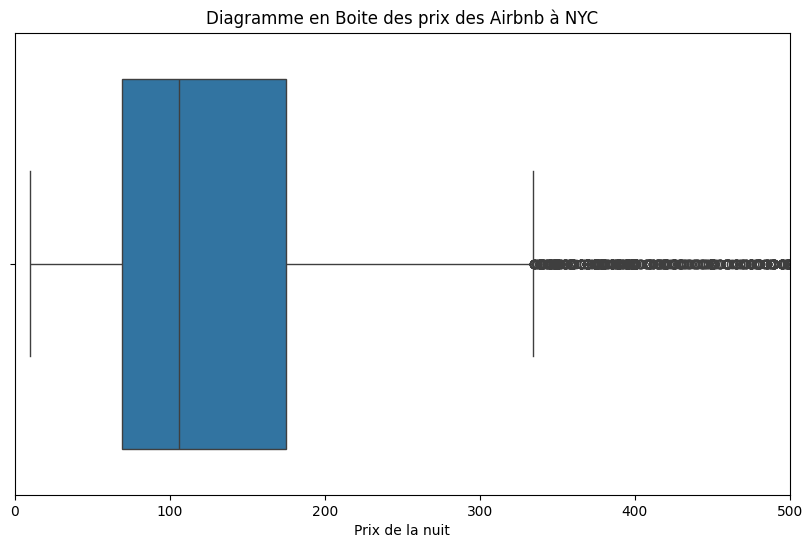

--- Les stats descriptives ---


count    48884.000000
mean       152.755053
std        240.170260
min         10.000000
25%         69.000000
50%        106.000000
75%        175.000000
max      10000.000000
Name: price, dtype: float64

In [33]:
#On retire les lignes avec 0 comme prix
df_clean = df[df['price'] > 0].copy()

plt.figure(figsize=(10, 6))
sns.boxplot(x=df_clean['price'])
plt.title('Diagramme en Boite des prix des Airbnb à NYC')
plt.xlabel("Prix de la nuit")
plt.xlim(0, 500)
plt.show()

print("--- Les stats descriptives ---")
df_clean['price'].describe()


#### Distribution des prix

In [26]:
#On limite les prix parce qu'un outliner existe (max = 10000)
df_with_lim = df_clean[df_clean['price'] <= 500]
df_with_lim['price'].describe()

count    47840.000000
mean       131.560807
std         88.050752
min         10.000000
25%         68.000000
50%        101.000000
75%        172.000000
max        500.000000
Name: price, dtype: float64

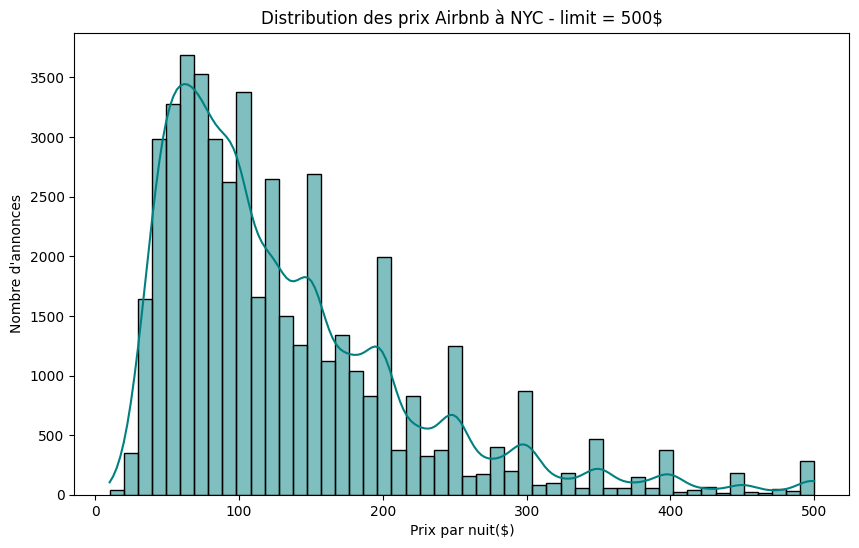

In [25]:
plt.figure(figsize=(10, 6))
sns.histplot(
    df_with_lim['price'],
    bins=50,
    kde=True,
    color='teal'
)

plt.title("Distribution des prix Airbnb à NYC - limit = 500$")
plt.xlabel("Prix par nuit($)")
plt.ylabel("Nombre d'annonces")
plt.show()

### ANALYSE NUIT ET DISPONIBILITES

#### Distribution des nuits minimum

In [ ]:
# df['minimum_nights'].isnull().sum()
df['minimum_nights'].describe()

np.int64(0)

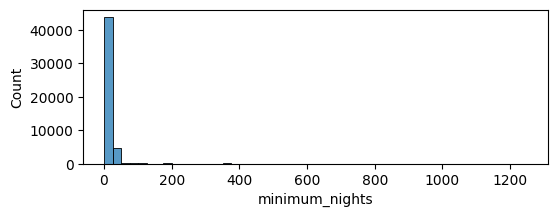

In [ ]:
plt.figure(figsize=(6, 2))
sns.histplot(
    df['minimum_nights'],
    bins=50
)
plt.show()

In [47]:
df_night = df[df['minimum_nights'] <= 40]
df_night['minimum_nights'].describe()

count    48390.000000
mean         5.711118
std          8.392196
min          1.000000
25%          1.000000
50%          2.000000
75%          5.000000
max         40.000000
Name: minimum_nights, dtype: float64

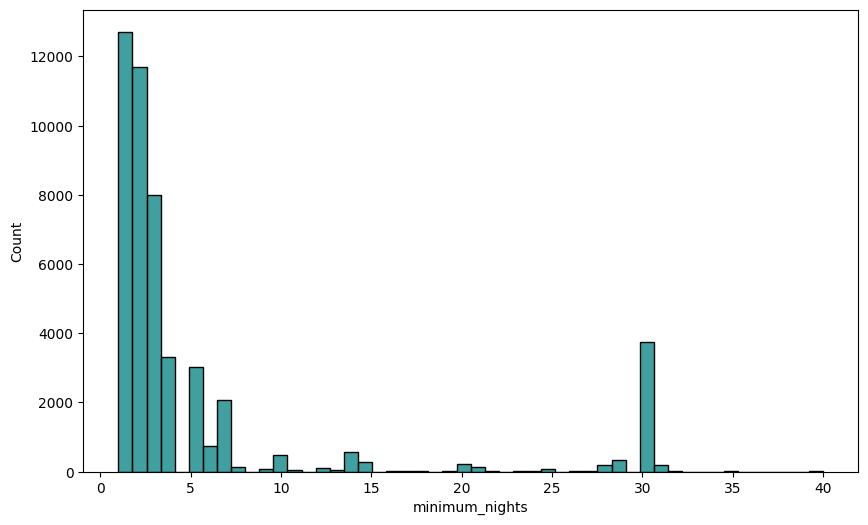

In [53]:
plt.figure(figsize=(10, 6))
sns.histplot(
    df_night['minimum_nights'],
    bins=50,
    color='teal'
)
plt.show()

#### Disponibilité sur l'année

In [ ]:
# df['availability_365'].isnull().sum()
df['availability_365'].describe()

count    48895.000000
mean       112.781327
std        131.622289
min          0.000000
25%          0.000000
50%         45.000000
75%        227.000000
max        365.000000
Name: availability_365, dtype: float64

In [63]:
df_dispo = df[df['availability_365'] > 0]
df_dispo['availability_365'].describe()

count    31362.000000
mean       175.831994
std        126.187636
min          1.000000
25%         55.000000
50%        168.000000
75%        305.000000
max        365.000000
Name: availability_365, dtype: float64

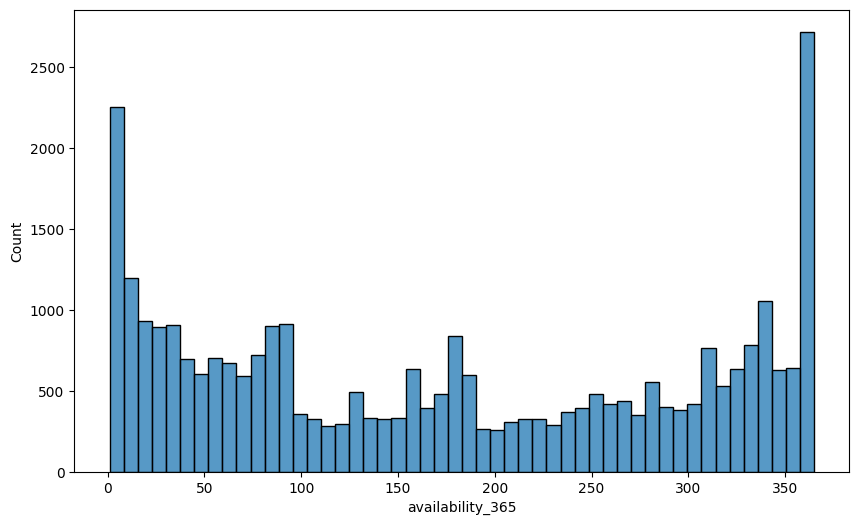

In [65]:
plt.figure(figsize=(10,6))

sns.histplot(
    df_dispo['availability_365'],
    bins=50
)
plt.show()

### LOCALISATION ET PRIX

#### Distribution entre les arrondissements

In [69]:
# df['neighbourhood_group'].isnull().sum()
df['neighbourhood_group'].unique()

array(['Brooklyn', 'Manhattan', 'Queens', 'Staten Island', 'Bronx'],
      dtype=object)

In [81]:
arrondissements = df['neighbourhood_group'].value_counts()
nom_arrondissement = arrondissements.index
taille = arrondissements.values
print(arrondissements)

neighbourhood_group
Manhattan        21661
Brooklyn         20104
Queens            5666
Bronx             1091
Staten Island      373
Name: count, dtype: int64


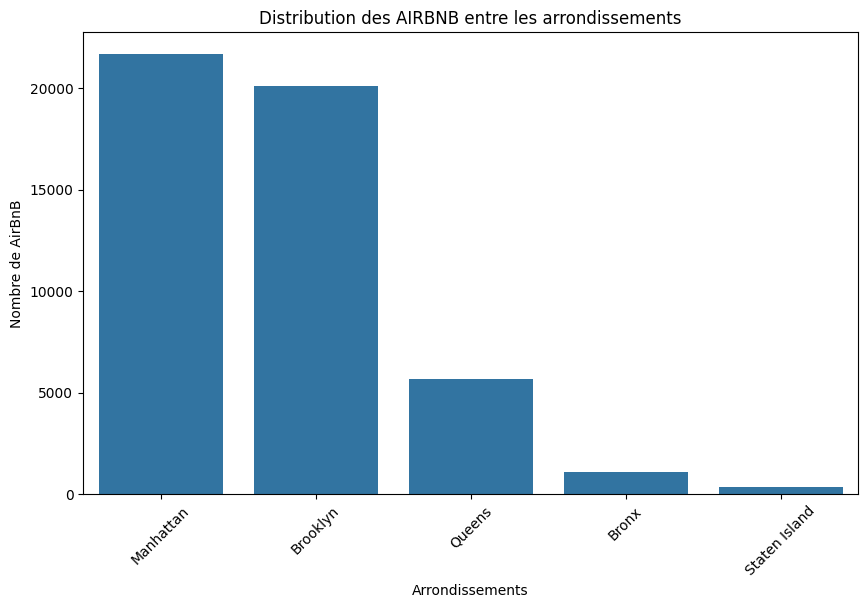

In [80]:
plt.figure(figsize=(10,6))

# plt.pie(
#     taille,
#     labels=nom_arrondissement,
#     autopct='%1.1f%%',
#     startangle=90,
#     wedgeprops={'edgecolor': 'black', 'linewidth': 1.5}
# )
# plt.axis('equal')
# plt.title("Distribution des AIRBNB entre les arrondissements")
# plt.show()

sns.barplot(x=nom_arrondissement, y=taille)
plt.title("Distribution des AIRBNB entre les arrondissements")
plt.xlabel("Arrondissements")
plt.ylabel("Nombre de AirBnB")
plt.xticks(rotation=45)
plt.show()

#### Les 10 quartiers avec le plus d'annonces

In [ ]:
quartiers = df['neighbourhood'].value_counts()
top_10 = quartiers.head(10)

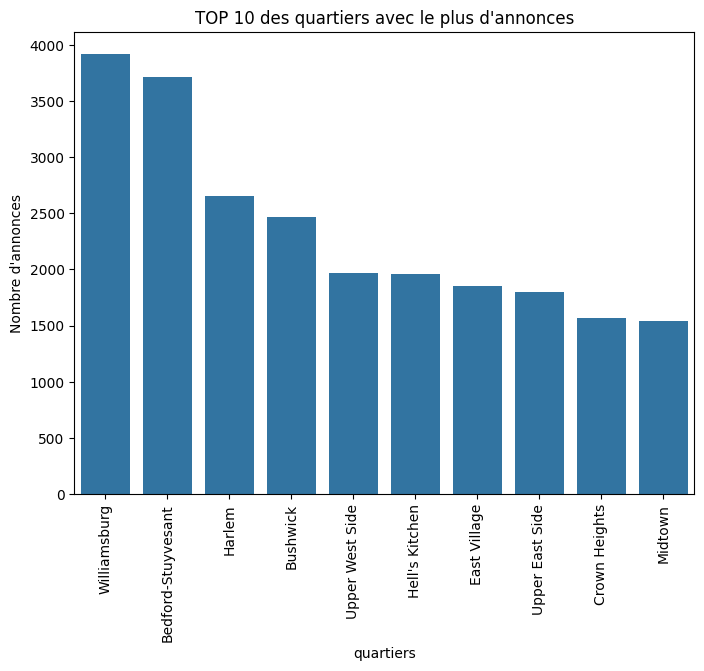

In [90]:
plt.figure(figsize=(8,6))

sns.barplot(x=top_10.index, y=top_10.values)
plt.title("TOP 10 des quartiers avec le plus d'annonces")
plt.xlabel("quartiers")
plt.ylabel("Nombre d'annonces")
plt.xticks(rotation=90)
plt.show()